# Detector de voz sintética em inglês: v5 (XLS-R da Meta × WavLM da Microsoft)

> **Um detector que classifica se uma voz em inglês foi gerada por IA**, treinado em inglês e testado também em pt-BR. Projeto final da liga Insper AI.

**Estado desta versão: fechada (2026-11-10).** A extração e as cabeças rodaram fora do notebook, uma vez por modelo (`scripts/rodar_v4.ps1 -Modelo xlsr` e `-Modelo wavlm` → `scripts/v4.py`); a comparação, por `scripts/comparar_v5.py`; e o **teste final foi avaliado uma única vez**, depois da decisão, com pré-registro escrito antes (`scripts/v5_teste.py`). **O notebook só lê do disco**: nada é treinado nem recalculado aqui. As figuras que dependem das notas por clipe (fora do git) só aparecem na máquina onde a v5 rodou.

## Histórico das versões (resumo)

- **v1 a v3** (CNN pequena sobre log-mel): boas na validação e **péssimas fora do domínio**: no dev_shift (vozes de internet do In-the-Wild), AUC de 0,15 a 0,38, abaixo do acaso.
- **v4** (XLS-R 300M da Meta, **congelado**, + regressão logística): resolveu a inversão (dev_shift AUC 0,983; In-the-Wild do teste 0,979). O ponto fraco que sobrou é o pt-BR e a escolha do limiar.
- **v5 (esta):** troca **só o modelo congelado** pelo WavLM Large (Microsoft) e compara os dois nos mesmos clipes.

**O que faz a célula abaixo:** lê os resultados de cada versão em `results/` e mostra uma linha por versão (na v4 e na v5, só a cabeça final). **Por quê:** quem abre o notebook vê de onde o projeto vem antes de ler a versão nova. Detalhes em `docs/HISTORICO_VERSOES.md`.

In [1]:
from pathlib import Path

import pandas as pd
from IPython.display import Markdown, display


def _pct(v):
    return "—" if pd.isna(v) else f"{100 * v:.1f}%"


def _n3(v):
    return "—" if pd.isna(v) else f"{v:.3f}"


linhas_h = []
b = pd.read_csv("results/baseline_results.csv", index_col=0)
linhas_h.append({"versão": "v1 (baseline, CNN)", "EER val (global)": _pct(b.loc["validação", "EER"]),
                 "dev_shift AUC": "—", "dev_shift EER": "—", "dev_shift acc. balanceada": "—",
                 "notebook": "notebooks/versions/v1_baseline.ipynb"})
e = pd.read_csv("results/experiments.csv")
for exp, g in e[e["versão"] == "v2"].groupby("experimento", sort=False):
    d = g[(g.conjunto == "dev_shift") & (g["avaliação"] == "janelas")].iloc[0]
    v = g[(g.conjunto == "validação") & (g.banco == "todas as fontes") & (g["avaliação"] == "central")].iloc[0]
    linhas_h.append({"versão": f"v2 · {exp} (CNN)", "EER val (global)": _pct(v.EER), "dev_shift AUC": _n3(d.AUC),
                     "dev_shift EER": _pct(d.EER), "dev_shift acc. balanceada": "—",
                     "notebook": "notebooks/versions/v2_augmentation.ipynb"})
a3 = pd.read_csv("results/v3_acuracias.csv")
for cond, g in a3.groupby("condição", sort=False):
    dv, vv = g[g.conjunto == "dev_shift"], g[g.conjunto == "validação"]
    linhas_h.append({"versão": f"v3 · {cond} (CNN, 3 seeds: média [mín a máx])",
                     "EER val (global)": _pct(vv.EER.mean()),
                     "dev_shift AUC": f"{dv.AUC.mean():.3f} [{dv.AUC.min():.3f} a {dv.AUC.max():.3f}]",
                     "dev_shift EER": _pct(dv.EER.mean()),
                     "dev_shift acc. balanceada": f"{dv['acurácia balanceada'].mean():.3f}",
                     "notebook": "notebooks/versions/v3_padding.ipynb"})
import json as _json

r4 = _json.loads(Path("results/v4_resumo.json").read_text(encoding="utf-8"))
c4 = pd.read_csv("results/v4_cabecas.csv")
f4 = c4[c4["cabeça"] == r4["cabeça_final_pela_validação"]].iloc[0]
linhas_h.append({"versão": f"v4 · {f4['cabeça']} (XLS-R)", "EER val (global)": _pct(f4["val EER global"]),
                 "dev_shift AUC": _n3(f4["dev AUC"]), "dev_shift EER": _pct(f4["dev EER"]),
                 "dev_shift acc. balanceada": _n3(f4["dev acurácia balanceada"]), "notebook": "notebooks/versions/v4_ssl.ipynb"})
for m, nome in (("xlsr", "XLS-R refeito, escolhido"), ("wavlm", "WavLM Large")):
    arq = Path(f"results/v5_{m}_cabecas.csv")
    if arq.exists():
        r5 = _json.loads(Path(f"results/v5_{m}_resumo.json").read_text(encoding="utf-8"))
        c5 = pd.read_csv(arq)
        f5 = c5[c5["cabeça"] == r5["cabeça_final_pela_validação"]].iloc[0]
        linhas_h.append({"versão": f"v5 · {f5['cabeça']} ({nome})", "EER val (global)": _pct(f5["val EER global"]),
                         "dev_shift AUC": _n3(f5["dev AUC"]), "dev_shift EER": _pct(f5["dev EER"]),
                         "dev_shift acc. balanceada": _n3(f5["dev acurácia balanceada"]),
                         "notebook": "notebook.ipynb (atual) = notebooks/versions/v5_wavlm.ipynb"})
display(Markdown(pd.DataFrame(linhas_h).to_markdown(index=False)))

| versão                                        | EER val (global)   | dev_shift AUC         | dev_shift EER   | dev_shift acc. balanceada   | notebook                                                   |
|:----------------------------------------------|:-------------------|:----------------------|:----------------|:----------------------------|:-----------------------------------------------------------|
| v1 (baseline, CNN)                            | 1.3%               | —                     | —               | —                           | notebooks/versions/v1_baseline.ipynb                       |
| v2 · v1r (CNN)                                | 1.4%               | 0.325                 | 63.7%           | —                           | notebooks/versions/v2_augmentation.ipynb                   |
| v2 · v2a (CNN)                                | 1.1%               | 0.386                 | 58.1%           | —                           | notebooks/versions/v2_augmentation.ipynb                   |
| v2 · v2b (CNN)                                | 2.0%               | 0.389                 | 57.0%           | —                           | notebooks/versions/v2_augmentation.ipynb                   |
| v3 · repeat (CNN, 3 seeds: média [mín a máx]) | 1.4%               | 0.282 [0.228 a 0.378] | 66.4%           | 0.456                       | notebooks/versions/v3_padding.ipynb                        |
| v3 · zero (CNN, 3 seeds: média [mín a máx])   | 1.4%               | 0.266 [0.146 a 0.377] | 67.8%           | 0.403                       | notebooks/versions/v3_padding.ipynb                        |
| v4 · concat_top3 (XLS-R)                      | 1.0%               | 0.983                 | 5.9%            | 0.897                       | notebooks/versions/v4_ssl.ipynb                            |
| v5 · concat_top3 (XLS-R refeito, escolhido)   | 1.0%               | 0.983                 | 6.0%            | 0.895                       | notebook.ipynb (atual) = notebooks/versions/v5_wavlm.ipynb |
| v5 · concat_top3 (WavLM Large)                | 1.1%               | 0.970                 | 7.5%            | 0.883                       | notebook.ipynb (atual) = notebooks/versions/v5_wavlm.ipynb |

## 1. Introdução

### 1.1 O que a v4 deixou
Com o XLS-R congelado e uma regressão logística por cima, o projeto passou de "ordena as vozes de internet ao contrário" (CNN, AUC 0,15 a 0,38 no dev_shift) para AUC 0,983. O grupo decidiu **comparar o modelo da Meta com um segundo modelo pronto** e seguir melhorando o melhor dos dois.

### 1.2 Por que o WavLM (e não o Gemini Embedding 2)
- O **Gemini Embedding 2** (Google) foi considerado e ficou de fora: só existe por **API paga**; no plano gratuito o Google usa os dados enviados para melhorar os produtos dele (problema com as licenças dos bancos); e ele é feito para captar **significado**, não detalhe acústico.
- O **WavLM Large** (`microsoft/wavlm-large`) se baixa e roda na nossa GPU, tem o mesmo formato do XLS-R (25 saídas de 1024 números a cada 20 ms) e é, junto com o XLS-R, um dos modelos mais usados em detecção de voz sintética. Então a troca é **uma mudança só**, num experimento limpo.

### 1.3 Como esses modelos aprenderam (sem rótulos e sem texto)
⚠️ Fora da trilha: modelos de fala auto-supervisionados. A ideia de usar um modelo pré-treinado e congelado como extrator de características é a de **transfer learning (Aula 10)**, lá com um modelo de imagem.
- **XLS-R (Meta, wav2vec 2.0):** cerca de 436 mil horas de fala em **128 línguas** (inclusive português). Durante o pré-treino, pedaços do áudio são **escondidos** e o modelo aprende a reconhecer qual era o pedaço certo entre vários errados: um "complete a lacuna" do som.
- **WavLM Large (Microsoft):** cerca de 94 mil horas de fala **só em inglês**. Faz o mesmo tipo de "complete a lacuna", mas recebe o áudio **sujo** (com ruído ou outra voz por cima) e tem de adivinhar como se ele estivesse limpo.
- Nenhum dos dois recebe texto. Por isso as representações guardam detalhes do **som**, que é onde ficam os artefatos de voz sintética. A **hipótese da v5** era que o treino com áudio sujo do WavLM ajudasse nas vozes de internet.

### 1.4 Pré-registro (resumo; texto completo em `docs/HISTORICO_VERSOES.md`, "v5 - pré-registro")
- **Uma mudança:** o modelo congelado. Mesmos clipes da v4, mesmo pré-processamento, mesmas cabeças, mesma escolha da cabeça (EER média por fonte na validação).
- **O XLS-R é refeito nesta máquina** para a comparação ser pareada; ele tem de reproduzir os números da v4 (no máximo 0,5 ponto de diferença por camada e a mesma cabeça final).
- **O WavLM é melhor** só se tiver EER média por fonte menor na validação **e** AUC maior no dev_shift, com o intervalo de 95% da diferença (bootstrap **por locutor**) sem o zero. **Pior:** o inverso. Senão, **empate, e segue o XLS-R**.
- **Teste final:** só depois da decisão, uma vez, com os dois modelos, **só para reportar**.

## 2. Configuração

**O que faz:** define **todos os hiperparâmetros numa célula só** (tag `config`), com a flag `QUICK` e `AVALIAR_TESTE_FINAL = False`. Na v5, o modelo é escolhido pela variável `V5_MODELO` (`xlsr` ou `wavlm`; sem ela, `wavlm`), e os arquivos de cada modelo levam o seu prefixo (`v5_xlsr_*`, `v5_wavlm_*`). **Por quê:** o `scripts/v4.py` executa exatamente esta célula em cada etapa, então os scripts nunca têm uma cópia própria dos hiperparâmetros, e os dois modelos rodam com a mesma configuração, mudando só o modelo.

In [2]:
import json
import os
from datetime import date
from pathlib import Path

import numpy as np
import pandas as pd

from src.analysis import FAIXAS_DURACAO, faixa_duracao
from src.metrics import eer_e_limiar, eer_media_por_fonte, metricas_completas

# ---------------- execução ----------------
QUICK = False                # True: teste rápido de ponta a ponta (~300 clipes, arquivos _quick)
QUICK = globals().get("QUICK_DO_SCRIPT", QUICK or os.environ.get("V4_QUICK") == "1")  # --quick / V4_QUICK=1
AVALIAR_TESTE_FINAL = False  # False: NADA do teste final é consultado nesta versão
VERSAO = "v5"

# ---------------- herdados (sem mudança) ----------------
SEED = 42                    # seed dos DADOS (amostras e sorteio dos shards de treino)
SAMPLE_RATE = 16_000
NUM_WORKERS = 4              # leitura de áudio; sobrescrito por V4_NUM_WORKERS (não muda o método)

# ---------------- modelo congelado (v5: a ÚNICA mudança em relação à v4) ----------------
# A v5 roda o mesmo pipeline duas vezes, uma por modelo, escolhido pela variável V5_MODELO
# (scripts/rodar_v4.ps1 -Modelo xlsr | wavlm). O XLS-R é refeito nesta máquina para a comparação ser pareada
# (mesmos clipes, mesmo hardware) e para conferir que os números batem com os da v4.
MODELOS_V5 = {"xlsr": "facebook/wav2vec2-xls-r-300m",   # Meta, a referência (v4)
              "wavlm": "microsoft/wavlm-large"}         # Microsoft, ~94 mil h de inglês
MODELO_V5 = os.environ.get("V5_MODELO", "wavlm")
MODELO_SSL = MODELOS_V5[MODELO_V5]
DTYPE = "float16"            # metade da memória e ~2x mais rápido; lote com NaN é refeito em bfloat16

# ---------------- pré-processamento (Parte D) ----------------
TOP_DB = 35.0                # corte do silêncio: quadros 35 dB abaixo do mais forte
MIN_S = 0.5                  # se o corte deixar menos que isso, usa o áudio sem corte
MAX_S = 8.0                  # recorte central de no máximo 8 s (sem completar)

# ---------------- extração (Parte D) ----------------
ORCAMENTO_H = 4.0            # orçamento CUMULATIVO de extração (results/<PREFIXO>_estado.json)
TAM_SHARD = 2000             # clipes por shard (~1 min de extração cada)
VAL_MAX = 20_000             # subamostra da validação
VAL_FONTE_PEQUENA = 5_000    # fontes com até isso entram inteiras (CodecFake+ e ShiftySpeech)
DEV_MAX = None               # None = dev_shift inteiro
TREINO_MAX_SHARDS = 20       # 40.000 clipes (20.000 reais + 20.000 fakes): o teto por fonte ainda vale
SEMCORTE = None             # v5: sem a ablação do corte (sem efeito na v4); não muda o sorteio dos outros clipes
MAX_AMOSTRAS_LOTE = 32 * 128_000   # lote da GPU: até 32 clipes de 8 s (pico ~4 GB na GPU)
MAX_CLIPES_LOTE = 64
BALDE_S = 2                  # lotes da GPU com formato fixo: 2, 4, 6 ou 8 s (memória; ver src/extracao_v4.py)
VAZAO_ESTIMADA = 44.0        # clipes/s medidos (500 clipes, 4 workers); só vale até a execução medir a sua

# ---------------- cabeças (Parte E) ----------------
GRADE_C = [1e-3, 1e-2, 1e-1, 1.0]   # regularização da regressão logística (C pequeno = mais regularizada)
RL_MAX_ITER = 1000
TOP_K_CONCAT = (3, 4)        # concatenação das 3 e das 4 melhores camadas (pela validação)
SEEDS_CABECA = (42, 123, 2026)
SOMA_LR, SOMA_WD = 1e-3, 1e-3
SOMA_MAX_EPOCAS, SOMA_PACIENCIA = 30, 5
SOMA_BATCH = 256
SOMA_BLOCO = 8192            # linhas lidas do disco de cada vez (~420 MB em float16)
SOMA_OCULTA = 256            # neurônios da camada escondida do MLP
SOMA_DROPOUT = 0.3           # o mesmo dropout da CNN das versões anteriores

if QUICK:
    TAM_SHARD, VAL_MAX, VAL_FONTE_PEQUENA, DEV_MAX, TREINO_MAX_SHARDS = 50, 100, 0, 100, 2
    ORCAMENTO_H = 0.5
    GRADE_C = [1e-2, 1.0]
    SOMA_MAX_EPOCAS, SOMA_PACIENCIA, SOMA_BLOCO = 3, 2, 64

HP = dict(SEED=SEED, SAMPLE_RATE=SAMPLE_RATE, NUM_WORKERS=NUM_WORKERS, MODELO_SSL=MODELO_SSL, DTYPE=DTYPE,
          TOP_DB=TOP_DB, MIN_S=MIN_S, MAX_S=MAX_S, ORCAMENTO_H=ORCAMENTO_H, TAM_SHARD=TAM_SHARD,
          VAL_MAX=VAL_MAX, VAL_FONTE_PEQUENA=VAL_FONTE_PEQUENA, DEV_MAX=DEV_MAX,
          TREINO_MAX_SHARDS=TREINO_MAX_SHARDS, SEMCORTE=SEMCORTE, MAX_AMOSTRAS_LOTE=MAX_AMOSTRAS_LOTE,
          MAX_CLIPES_LOTE=MAX_CLIPES_LOTE, BALDE_S=BALDE_S, VAZAO_ESTIMADA=VAZAO_ESTIMADA, GRADE_C=GRADE_C,
          RL_MAX_ITER=RL_MAX_ITER, TOP_K_CONCAT=TOP_K_CONCAT, SEEDS_CABECA=SEEDS_CABECA, SOMA_LR=SOMA_LR,
          SOMA_WD=SOMA_WD, SOMA_MAX_EPOCAS=SOMA_MAX_EPOCAS, SOMA_PACIENCIA=SOMA_PACIENCIA,
          SOMA_BATCH=SOMA_BATCH, SOMA_BLOCO=SOMA_BLOCO, SOMA_OCULTA=SOMA_OCULTA, SOMA_DROPOUT=SOMA_DROPOUT)
# o que define o MÉTODO da extração (se mudar, o cache antigo não serve: o script para sem apagar nada)
CFG_EXTRACAO = dict(modelo=MODELO_SSL, dtype=DTYPE, top_db=TOP_DB, min_s=MIN_S, max_s=MAX_S, sr=SAMPLE_RATE,
                    resumo="média e desvio no tempo das 25 saídas, só quadros válidos")

# ---------------- arquivos (QUICK separado dos oficiais) ----------------
SUFIXO = ("_quick" + os.environ.get("V4_SUFIXO_EXTRA", "")) if QUICK else ""   # extra: só testes do QUICK
PREFIXO = f"v5_{MODELO_V5}"                                   # v5_xlsr / v5_wavlm: arquivos separados por modelo
CACHE_DIR = Path("data/processed") / f"{PREFIXO}_cache{SUFIXO}"  # fora do git (data/**)
RESULTS_DIR, MODELS_DIR, LOGS_DIR = Path("results"), Path("models"), Path("logs")
ETAPAS = ("extracao", "camadas", "somas", "atalhos", "resumo")
ARQ_ESTADO = RESULTS_DIR / f"{PREFIXO}_estado{SUFIXO}.json"          # orçamento cumulativo de extração
ARQ_CONCLUIDO = RESULTS_DIR / f"{PREFIXO}_concluido{SUFIXO}.json"    # gravado por último


def arq_result(nome, ext):
    return RESULTS_DIR / f"{PREFIXO}_{nome}{SUFIXO}.{ext}"


def marcador(etapa):
    return RESULTS_DIR / f"{PREFIXO}_{etapa}_concluido{SUFIXO}.json"


print(f"{VERSAO} | QUICK = {QUICK} | AVALIAR_TESTE_FINAL = {AVALIAR_TESTE_FINAL} | modelo {MODELO_SSL} ({DTYPE}) | prefixo {PREFIXO}")
print(f"cache: {CACHE_DIR} | orçamento de extração: {ORCAMENTO_H} h | treino: até {TREINO_MAX_SHARDS} shards "
      f"de {TAM_SHARD} | validação até {VAL_MAX} | dev_shift {'inteiro' if DEV_MAX is None else DEV_MAX}")

v5 | QUICK = False | AVALIAR_TESTE_FINAL = False | modelo microsoft/wavlm-large (float16) | prefixo v5_wavlm
cache: data\processed\v5_wavlm_cache | orçamento de extração: 4.0 h | treino: até 20 shards de 2000 | validação até 20000 | dev_shift inteiro


**O que mudou em relação à v4 (uma frase cada):**

| hiperparâmetro | valor na v5 | por quê |
|:--|:--|:--|
| `MODELOS_V5` / `MODELO_SSL` | XLS-R 300M (Meta) e WavLM Large (Microsoft) | a pergunta da versão; os dois têm 25 saídas de 1024 a cada 20 ms e a mesma normalização da entrada |
| `PREFIXO` | `v5_xlsr` / `v5_wavlm` | resultados e caches separados por modelo, sem tocar nos arquivos da v4 |
| `SEMCORTE` | `None` | a ablação do corte de silêncio não teve efeito na v4; tirá-la não muda o sorteio dos outros clipes |

Todo o resto é **igual à v4** (justificativas em `notebooks/versions/v4_ssl.ipynb`, seção 2): fp16, corte de silêncio de 35 dB, até 8 s, 40.000 clipes de treino, 19.999 da validação, dev_shift inteiro (10.614), grade de C, concatenação das 3 e 4 melhores camadas, somas ponderadas com 3 seeds. A placa mudou (RTX 4050 de 6 GB): o WavLM usou 3,8 GB de GPU com o mesmo lote, então nada de execução precisou mudar.

**O que faz:** importa o matplotlib, define as cores (laranja = XLS-R/Meta, azul = WavLM/Microsoft) e funções para ler os arquivos de cada modelo. **Por quê:** as mesmas cores em todas as figuras e um único lugar com os nomes dos arquivos.

In [3]:
import matplotlib.pyplot as plt

COR = {"xlsr": "#eb6834", "wavlm": "#2a78d6"}
NOME = {"xlsr": "XLS-R (Meta)", "wavlm": "WavLM (Microsoft)"}
plt.rcParams.update({"figure.dpi": 80, "axes.grid": True, "grid.alpha": 0.3})
pd.set_option("display.width", 200)


def r5(m, nome, ext):
    """Arquivo de resultado de um modelo da v5 (results/v5_<modelo>_<nome>.<ext>)."""
    return RESULTS_DIR / f"v5_{m}_{nome}{SUFIXO}.{ext}"


def ler_json(p):
    return json.loads(Path(p).read_text(encoding="utf-8"))


def existe(p):
    return Path(p).exists()


def pendente(o_que):
    display(Markdown(f"> **Pendente:** {o_que} não está no disco (arquivo fora do git ou etapa não rodada)."))

## 3. Mapa do banco (resumo)

O banco **não mudou** desde a v2 (mesmo manifest e mesmos splits); o mapa completo está em `docs/dataset_overview.md` e em `notebooks/versions/v1_baseline.ipynb`. O que importa na v5 é que **os dois modelos viram exatamente os mesmos clipes**, e que eles são os mesmos da v4.

**O que faz:** lê o plano de extração dos dois modelos, confere que é idêntico e mostra quantos clipes de cada fonte e classe entraram. **Por quê:** a comparação só é justa se for nos mesmos clipes.

In [4]:
planos = {m: Path("data/processed") / f"v5_{m}_cache{SUFIXO}" / "plano.parquet" for m in ("xlsr", "wavlm")}
if all(existe(p) for p in planos.values()):
    pa, pb = (pd.read_parquet(p) for p in planos.values())
    print("planos dos dois modelos idênticos:", pa[["idx_manifest", "conjunto"]].equals(pb[["idx_manifest", "conjunto"]]))
    from src.experimento import ler_manifest
    df = ler_manifest()
    pm = pa.join(df[["source_dataset", "label"]], on="idx_manifest")
    t = (pm.assign(classe=pm.label.map({0: "real", 1: "fake"}))
           .pivot_table(index=["conjunto", "source_dataset"], columns="classe", values="idx_manifest", aggfunc="size",
                        fill_value=0, sort=False))
    display(t)
    print(pm.groupby("conjunto", sort=False).size().to_string())
else:
    pendente("o plano de extração (data/processed/v5_*_cache/plano.parquet)")

planos dos dois modelos idênticos: True


classe                     real   fake
conjunto  source_dataset              
dev_shift in_the_wild      8633   1981
val       shiftyspeech     1157   3471
          dfadd            2831  10336
          librispeech      1852      0
          codecfake_plus    164    188
treino    shiftyspeech     4707   6413
          dfadd            4864   6413
          librispeech      4863      0
          codecfake_plus    702    743
          asvspoof2019_la  4864   6431

conjunto
dev_shift    10614
val          19999
treino       40000


**Conclusão:** 40.000 clipes de treino (metade real, metade fake), 19.999 da validação e o dev_shift inteiro (10.614), os mesmos para os dois modelos e os mesmos tamanhos da v4.

## 4. Visualização: o que cada modelo "acha" das vozes de internet

**O que faz:** para a cabeça final de cada modelo, mostra o histograma da nota (logit) dos reais e dos fakes do dev_shift, com o limiar fixado na validação. **Por quê:** é a forma mais direta de ver a diferença: quanto mais separadas as duas montanhas, melhor; reais à direita do limiar são falsos alarmes.

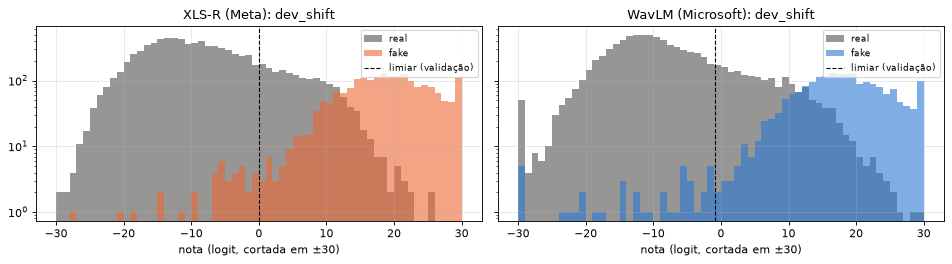

In [5]:
cmp_ = ler_json(RESULTS_DIR / f"v5_comparacao{SUFIXO}.json") if existe(RESULTS_DIR / f"v5_comparacao{SUFIXO}.json") else None
arqs = {m: r5(m, f"notas_{cmp_['sistemas']['final']['cabeças'][m]}_dev_shift", "parquet") for m in ("xlsr", "wavlm")} if cmp_ else {}
if cmp_ and all(existe(p) for p in arqs.values()):
    fig, axes = plt.subplots(1, 2, figsize=(12, 3.4), sharey=True)
    for ax, m in zip(axes, ("xlsr", "wavlm")):
        d = pd.read_parquet(arqs[m])
        z = d.z.clip(-30, 30)
        bins = np.linspace(-30, 30, 61)
        ax.hist(z[d.label == 0], bins, alpha=0.6, color="#52514e", label="real")
        ax.hist(z[d.label == 1], bins, alpha=0.6, color=COR[m], label="fake")
        ax.axvline(cmp_["sistemas"]["final"][m]["limiar_val_logit"], color="black", ls="--", lw=1, label="limiar (validação)")
        ax.set(title=f"{NOME[m]}: dev_shift", xlabel="nota (logit, cortada em ±30)", yscale="log")
        ax.legend(fontsize=8)
    fig.tight_layout()
    plt.show()
else:
    pendente("as notas por clipe do dev_shift (results/v5_*_notas_*_dev_shift.parquet, fora do git)")

**Conclusão:** nos dois modelos, quase todos os fakes ficam à direita do limiar (recall de 98% nos dois), e o problema está nos **reais com nota alta**: no limiar da validação, 19,1% dos reais do dev_shift são acusados no XLS-R e 21,3% no WavLM. O WavLM também tem alguns fakes com nota muito baixa (à esquerda, perto de −30), erros "com muita certeza" que quase não aparecem no XLS-R. Como o limiar vem da validação (áudio de estúdio), ele acusa demais em áudio de internet nos dois modelos.

## 5. Análise exploratória

### 5.1 Quanto cada modelo "sabe" de onde veio o áudio (atalhos)
**O que faz:** mostra a parte (b) do diagnóstico de atalhos de cada modelo: com só os áudios **reais**, uma regressão tenta adivinhar **de qual banco** o áudio veio, usando a melhor camada do modelo (e, como comparação, só estatísticas baratas: duração, silêncio, volume e banda). **Por quê:** se o modelo reconhece muito bem o banco de origem, ele guarda informação de gravação/canal, que pode virar atalho ("estúdio = real").

In [6]:
linhas = []
for m in ("xlsr", "wavlm"):
    if existe(r5(m, "atalhos", "json")):
        a = ler_json(r5(m, "atalhos", "json"))
        linhas.append({"modelo": NOME[m], "camada": a["b_fonte_por_camada"]["camada"],
                       "acc. balanceada (fonte dos reais, camada)": a["b_fonte_por_camada"]["acurácia balanceada"],
                       "acc. balanceada (só estatísticas)": a["b_fonte_por_estatisticas"]["acurácia balanceada"],
                       "acaso": a["b_fonte_por_estatisticas"]["acaso (1/nº de fontes da validação)"],
                       "controle (rótulos embaralhados): val AUC": a["d_controle_rotulos_embaralhados"]["val AUC"]})
display(pd.DataFrame(linhas).round(3)) if linhas else pendente("os atalhos")

,modelo,camada,"acc. balanceada (fonte dos reais, camada)",acc. balanceada (só estatísticas),acaso,controle (rótulos embaralhados): val AUC
0,XLS-R (Meta),7,0.798,0.571,0.25,0.475
1,WavLM (Microsoft),4,0.821,0.571,0.25,0.446


**Conclusão:** os dois modelos reconhecem o banco de origem dos reais muito acima do acaso (≈ 0,80 contra 0,25), bem mais que as estatísticas baratas (0,57): os dois guardam informação de gravação. O WavLM não guarda menos que o XLS-R, então o pré-treino com áudio sujo não "apagou" o canal. O controle com rótulos embaralhados dá AUC perto de 0,5, como deve.

## 6. Treinamento

### 6.1 Extração: tempo e conferência de reprodução
**O que faz:** lê o marcador de extração de cada modelo (tempo, clipes) e compara, camada a camada, o XLS-R refeito com a v4. **Por quê:** o pré-registro exige que o XLS-R refeito reproduza a v4 antes de comparar os modelos.

In [7]:
for m in ("xlsr", "wavlm"):
    p = r5(m, "extracao_concluido", "json")
    if existe(p):
        e = ler_json(p)
        print(f"{NOME[m]}: {e['horas_extracao_acumuladas']:.2f} h de extração | {e['parou_por']} | "
              + ", ".join(f"{k} {v['clipes_prontos']}" for k, v in e["conjuntos"].items()))
if existe(r5("xlsr", "camadas", "csv")):
    a, b = pd.read_csv("results/v4_camadas.csv"), pd.read_csv(r5("xlsr", "camadas", "csv"))
    dif = 100 * (b["val EER média por fonte"] - a["val EER média por fonte"])
    print(f"reprodução (XLS-R v5 × v4): maior diferença de EER média por fonte por camada = {dif.abs().max():.2f} ponto "
          f"(camada {int(dif.abs().idxmax())}); cabeça final v4 = {r4['cabeça_final_pela_validação']}, "
          f"v5 = {ler_json(r5('xlsr', 'resumo', 'json'))['cabeça_final_pela_validação']}")

XLS-R (Meta): 1.70 h de extração | plano completo | dev_shift 10614, val 19999, treino 40000
WavLM (Microsoft): 1.54 h de extração | plano completo | dev_shift 10614, val 19999, treino 40000
reprodução (XLS-R v5 × v4): maior diferença de EER média por fonte por camada = 0.37 ponto (camada 11); cabeça final v4 = concat_top3, v5 = concat_top3


**Conclusão:** o XLS-R refeito reproduziu a v4 (no máximo 0,37 ponto por camada; a mesma cabeça `concat_top3`, com 5,92%), então a comparação é nos mesmos clipes e com o mesmo código. O WavLM levou mais tempo de extração (sua atenção é mais pesada).

### 6.2 As 25 camadas dos dois modelos lado a lado
**O que faz:** para cada saída do modelo (0 = entrada do transformer, 24 = última camada), a EER média por fonte na validação (escolhe) e a AUC no dev_shift (só reportada), dos dois modelos. **Por quê:** é a figura que explica **onde** cada modelo guarda as pistas da voz sintética.

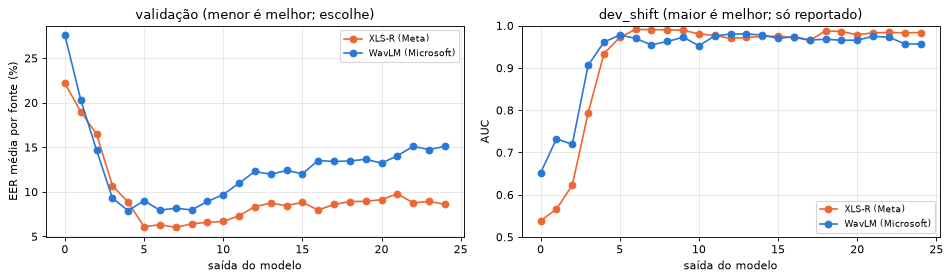

,camada,C xlsr,val EER média por fonte xlsr,dev AUC xlsr,dev EER xlsr,dev acurácia balanceada xlsr,C wavlm,val EER média por fonte wavlm,dev AUC wavlm,dev EER wavlm,dev acurácia balanceada wavlm
0,0,1.00,0.222,0.538,0.483,0.551,1.00,0.276,0.652,0.358,0.629
1,1,0.10,0.190,0.566,0.452,0.563,1.00,0.203,0.732,0.294,0.669
2,2,1.00,0.165,0.623,0.398,0.545,0.10,0.147,0.719,0.337,0.678
3,3,1.00,0.107,0.793,0.271,0.678,0.10,0.093,0.906,0.160,0.828
4,4,0.01,0.088,0.934,0.133,0.796,0.10,0.079,0.961,0.083,0.855
5,5,0.10,0.061,0.973,0.075,0.874,0.01,0.090,0.978,0.062,0.890
6,6,0.01,0.063,0.991,0.035,0.913,0.10,0.080,0.970,0.086,0.881
7,7,0.01,0.060,0.991,0.035,0.935,1.00,0.082,0.955,0.098,0.891
8,8,0.01,0.064,0.990,0.038,0.926,0.10,0.080,0.963,0.079,0.885
9,9,0.01,0.066,0.989,0.038,0.912,0.01,0.089,0.973,0.071,0.889


In [8]:
arq = RESULTS_DIR / f"v5_comparacao_camadas{SUFIXO}.csv"
if existe(arq):
    cc = pd.read_csv(arq)
    fig, ax = plt.subplots(1, 2, figsize=(12, 3.6))
    for m in ("xlsr", "wavlm"):
        ax[0].plot(cc.camada, 100 * cc[f"val EER média por fonte {m}"], "o-", color=COR[m], label=NOME[m])
        ax[1].plot(cc.camada, cc[f"dev AUC {m}"], "o-", color=COR[m], label=NOME[m])
    ax[0].set(xlabel="saída do modelo", ylabel="EER média por fonte (%)", title="validação (menor é melhor; escolhe)")
    ax[1].set(xlabel="saída do modelo", ylabel="AUC", title="dev_shift (maior é melhor; só reportado)", ylim=(0.5, 1))
    for a_ in ax:
        a_.legend(fontsize=8)
    fig.tight_layout()
    plt.show()
    display(cc.round(3))
else:
    pendente("a comparação por camada")

**Conclusão:** no **XLS-R**, as camadas do meio (5 a 9) são todas boas (≈ 6% na validação). No **WavLM**, as melhores são as **de baixo** (3 e 4), e a qualidade **cai rápido depois da 8** (camada 24: 15,1% × 8,6%). Nas camadas 0 a 4, o WavLM vai até melhor que o XLS-R no dev_shift. Hipótese (não testada): o pré-treino a "limpar" ruído e outra voz faz as camadas de cima do WavLM jogarem fora justamente os detalhes acústicos que denunciam a voz sintética.

### 6.3 Cabeças de cada modelo
**O que faz:** mostra todas as cabeças de cada modelo (melhor camada, concatenações, somas ponderadas com 3 seeds) com a EER média por fonte da validação (que escolhe) e as métricas do dev_shift. **Por quê:** a cabeça final de cada modelo sai daqui, pela regra da v4.

In [9]:
for m in ("xlsr", "wavlm"):
    if existe(r5(m, "cabecas", "csv")):
        t = pd.read_csv(r5(m, "cabecas", "csv"))
        t = t[~t["cabeça"].astype(str).str.contains("atalho")]
        cols = ["cabeça", "seed", "val EER média por fonte", "val EER global", "dev AUC", "dev EER",
                "dev acurácia balanceada", "dev acurácia balanceada (0,5)"]
        display(Markdown(f"**{NOME[m]}** (cabeça final pela validação: `{ler_json(r5(m, 'resumo', 'json'))['cabeça_final_pela_validação']}`)"))
        display(t[cols].round(4))

**XLS-R (Meta)** (cabeça final pela validação: `concat_top3`)

,cabeça,seed,val EER média por fonte,val EER global,dev AUC,dev EER,dev acurácia balanceada,"dev acurácia balanceada (0,5)"
0,rl_camada_7,-,0.0602,0.0123,0.9907,0.0352,0.9348,0.9311
1,concat_top3,-,0.0592,0.0105,0.9826,0.0604,0.8954,0.8953
2,concat_top4,-,0.0596,0.0105,0.9897,0.0409,0.9174,0.9138
3,soma_linear,42,0.0664,0.0124,0.9819,0.0498,0.9044,0.9089
4,soma_linear,123,0.0685,0.0127,0.9822,0.0492,0.9071,0.9141
5,soma_linear,2026,0.0672,0.0130,0.9816,0.0494,0.9002,0.9052
6,soma_linear_ensemble,média das 3,0.0651,0.0125,0.9819,0.0495,0.9045,0.9088
7,soma_mlp,42,0.0657,0.0115,0.9839,0.0633,0.8928,0.8856
8,soma_mlp,123,0.0663,0.0134,0.9828,0.0654,0.9129,0.9082
9,soma_mlp,2026,0.0666,0.0133,0.9882,0.0470,0.9247,0.9240


**WavLM (Microsoft)** (cabeça final pela validação: `concat_top3`)

,cabeça,seed,val EER média por fonte,val EER global,dev AUC,dev EER,dev acurácia balanceada,"dev acurácia balanceada (0,5)"
0,rl_camada_4,-,0.0790,0.0181,0.9610,0.0833,0.8550,0.8433
1,concat_top3,-,0.0677,0.0114,0.9700,0.0751,0.8835,0.8924
2,concat_top4,-,0.0709,0.0114,0.9657,0.0786,0.8871,0.8960
3,soma_linear,42,0.0808,0.0158,0.9760,0.0748,0.8904,0.9026
4,soma_linear,123,0.0786,0.0142,0.9719,0.0778,0.8740,0.8898
5,soma_linear,2026,0.0794,0.0141,0.9670,0.0858,0.8692,0.8831
6,soma_linear_ensemble,média das 3,0.0816,0.0145,0.9720,0.0790,0.8768,0.8921
7,soma_mlp,42,0.0870,0.0158,0.9623,0.0995,0.8958,0.9101
8,soma_mlp,123,0.0895,0.0157,0.9656,0.0974,0.8875,0.8985
9,soma_mlp,2026,0.0884,0.0153,0.9557,0.0999,0.9038,0.9075


**Conclusão:** nos dois modelos, a validação escolhe a `concat_top3` (XLS-R: camadas 5, 6, 7; WavLM: camadas 4, 6, 8). As somas ponderadas (que aprendem o peso de cada camada) não ganham das concatenações em nenhum dos dois.

## 7. Avaliação

### 7.1 A decisão (validação + dev_shift)
**O que faz:** mostra a comparação pré-registrada: EER média por fonte na validação e AUC no dev_shift da cabeça final de cada modelo, e o bootstrap pareado **por locutor** da diferença no dev_shift (16 locutores, 1.000 reamostragens). Também a "só última camada", só reportada. **Por quê:** é a regra que decide; o teste final não entra aqui.

⚠️ Fora da trilha: o bootstrap (reamostragem com reposição) para medir a incerteza de uma diferença.

In [10]:
if cmp_:
    linhas = []
    for sis, info in cmp_["sistemas"].items():
        for m in ("xlsr", "wavlm"):
            i = info[m]
            linhas.append({"sistema": sis, "modelo": NOME[m], "cabeça": info["cabeças"][m],
                           "val EER média por fonte": i["val EER média por fonte"], "dev AUC": i["dev AUC"],
                           "dev EER": i["dev EER"], "dev acc. balanceada (limiar val)": i["dev acurácia balanceada"],
                           "dev acurácia": i["dev acurácia"], "dev acurácia trivial": info["dev acurácia trivial"]})
    display(pd.DataFrame(linhas).round(4))
    for sis, info in cmp_["sistemas"].items():
        b = info["bootstrap_dev_por_locutor"]
        print(f"{sis}: WavLM − XLS-R no dev_shift: AUC {b['dif AUC (b - a)']:+.4f} "
              f"(IC95 {b['dif AUC IC95'][0]:+.4f} a {b['dif AUC IC95'][1]:+.4f}) | EER {100 * b['dif EER (b - a)']:+.2f} ponto "
              f"(IC95 {100 * b['dif EER IC95'][0]:+.2f} a {100 * b['dif EER IC95'][1]:+.2f})")
    display(Markdown(f"**Decisão (pré-registro):** {cmp_['decisao']['texto']}"))
else:
    pendente("a comparação (python scripts/comparar_v5.py)")

,sistema,modelo,cabeça,val EER média por fonte,dev AUC,dev EER,dev acc. balanceada (limiar val),dev acurácia,dev acurácia trivial
0,final,XLS-R (Meta),concat_top3,0.0592,0.9826,0.0604,0.8954,0.8412,0.8134
1,final,WavLM (Microsoft),concat_top3,0.0677,0.9700,0.0751,0.8835,0.8228,0.8134
2,ultima_camada,XLS-R (Meta),rl_camada_24,0.0862,0.9838,0.0631,0.8690,0.7948,0.8134
3,ultima_camada,WavLM (Microsoft),rl_camada_24,0.1510,0.9563,0.0996,0.8819,0.8262,0.8134


final: WavLM − XLS-R no dev_shift: AUC -0.0126 (IC95 -0.0614 a +0.0014) | EER +1.47 ponto (IC95 -0.95 a +9.35)
ultima_camada: WavLM − XLS-R no dev_shift: AUC -0.0275 (IC95 -0.1001 a +0.0111) | EER +3.65 ponto (IC95 -2.87 a +12.80)


**Decisão (pré-registro):** EMPATE pela regra (validação e dev_shift não concordam ou o intervalo inclui zero): segue o xlsr

**Conclusão:** o WavLM ficou **pior na validação** (6,77% × 5,92%) e **pior no dev_shift** (AUC 0,970 × 0,983). Mas o intervalo da diferença no dev_shift vai de −0,061 a **+0,001**: encosta no zero, porque são só 16 locutores. Pela regra, **empate, e o projeto segue com o XLS-R**.

### 7.2 Onde cada modelo erra: fontes, geradores, duração e locutores
**O que faz:** com as cabeças finais, mostra a EER por fonte e por gerador na validação e a AUC por faixa de duração e por locutor no dev_shift. **Por quê:** é o "porquê" da comparação (descritivo; não muda a decisão).

In [11]:
for nome, titulo in (("fontes", "EER e AUC por fonte (validação)"), ("geradores", "EER por gerador (validação; fakes do gerador × todos os reais)"),
                     ("duracao", "por faixa de duração (dev_shift; falso alarme e recall no limiar da validação)"),
                     ("locutores", "por locutor (dev_shift)")):
    arq = RESULTS_DIR / f"v5_comparacao_{nome}{SUFIXO}.csv"
    if existe(arq):
        display(Markdown(f"**{titulo}**"))
        display(pd.read_csv(arq).round(3))

**EER e AUC por fonte (validação)**

,source_dataset,n real,n fake,AUC z_xlsr,EER z_xlsr,AUC z_wavlm,EER z_wavlm
0,codecfake_plus,164,188,0.903,0.148,0.883,0.174
1,dfadd,2831,10336,1.000,0.000,1.000,0.001
2,librispeech,1852,0,NaN,NaN,NaN,NaN
3,shiftyspeech,1157,3471,0.997,0.029,0.996,0.029


**EER por gerador (validação; fakes do gerador × todos os reais)**

,gerador,fonte,n fake,EER z_xlsr,EER z_wavlm
0,ELLAV,codecfake_plus,8,0.000,0.001
1,GPST,codecfake_plus,30,0.090,0.036
2,GradTTS,dfadd,2031,0.006,0.004
3,MatchaTTS,dfadd,2074,0.004,0.005
4,NS2,codecfake_plus,23,0.001,0.001
5,NaturalSpeech2,dfadd,2051,0.003,0.003
6,PflowTTS,dfadd,2128,0.007,0.007
7,RALLE,codecfake_plus,5,0.003,0.001
8,SIMPLESPEECH1,codecfake_plus,32,0.163,0.154
9,SIMPLESPEECH2,codecfake_plus,31,0.064,0.072


**por faixa de duração (dev_shift; falso alarme e recall no limiar da validação)**

,faixa,n real,n fake,AUC z_xlsr,EER z_xlsr,recall fake z_xlsr,falso alarme z_xlsr,AUC z_wavlm,EER z_wavlm,recall fake z_wavlm,falso alarme z_wavlm
0,< 2 s,2067,353,0.931,0.133,0.941,0.317,0.915,0.145,0.946,0.345
1,2 a < 4 s,3772,759,0.987,0.065,0.988,0.189,0.975,0.075,0.983,0.221
2,≥ 4 s,2794,869,0.997,0.021,0.993,0.101,0.994,0.031,0.992,0.106


**por locutor (dev_shift)**

,speaker_id,n real,n fake,AUC z_xlsr,EER z_xlsr,recall fake z_xlsr,falso alarme z_xlsr,AUC z_wavlm,EER z_wavlm,recall fake z_wavlm,falso alarme z_wavlm
0,itw:Arnold Schwarzenegger,243,108,1.000,0.011,1.000,0.156,0.999,0.015,1.000,0.276
1,itw:Barack Obama,3302,334,0.988,0.040,0.970,0.088,0.991,0.018,0.991,0.102
2,itw:Donald Trump,3268,155,0.973,0.079,0.845,0.022,0.910,0.123,0.781,0.021
3,itw:Dwight Eisenhower,205,63,0.973,0.026,1.000,0.985,0.949,0.096,1.000,0.976
4,itw:Frank Sinatra,17,38,0.861,0.193,1.000,0.882,0.834,0.236,1.000,0.941
5,itw:Gilbert Gottfried,81,127,1.000,0.018,1.000,0.210,1.000,0.000,1.000,0.099
6,itw:Harry Truman,47,16,1.000,0.000,1.000,0.489,1.000,0.000,1.000,0.362
7,itw:Jerry Seinfeld,8,43,0.997,0.012,1.000,0.125,0.994,0.023,1.000,0.125
8,itw:John Cleese,59,70,1.000,0.000,1.000,0.712,0.996,0.031,1.000,0.271
9,itw:Lyndon Johnson,95,12,0.989,0.105,1.000,0.747,0.996,0.005,1.000,0.421


**Conclusão:**
- **Fontes:** empate no DFADD e no ShiftySpeech; o WavLM é pior no **CodecFake+** (fakes de codec neural; EER 17,4% × 14,8%).
- **Duração:** o XLS-R é melhor nas três faixas; a maior diferença é nos áudios **curtos** (< 2 s).
- **Locutores:** boa parte da diferença do dev_shift vem de **Winston Churchill** (gravações antigas: AUC 0,980 no XLS-R × 0,707 no WavLM) e de Donald Trump. Gravação antiga, de novo, é o ponto fraco.
- **Limiar:** nos dois modelos, o limiar da validação (estúdio) dá muito falso alarme em alguns locutores do dev_shift (por exemplo, Eisenhower): o problema do limiar por domínio continua.

### 7.3 Teste final (avaliado uma única vez, depois da decisão)
**O que faz:** lê o resultado do teste final (`scripts/v5_teste.py`): os mesmos 51.320 clipes do teste da v4, quatro sistemas (X1/X2 = XLS-R só camada 24 / cabeça final; W1/W2 = o mesmo com o WavLM), dois limiares (A = ponto de EER da validação; B = ponto de EER do dev_shift), com intervalos bootstrap. **Por quê:** é o número para o relatório; o pré-registro diz que ele **não muda** a decisão.

**Limiar A** (ponto de EER da validação):

métrica,acurácia balanceada,AUC,EER,falso alarme real,acurácia balanceada,AUC,EER,falso alarme real,acurácia balanceada,AUC,EER,falso alarme real,acurácia balanceada,AUC,EER,falso alarme real
sistema,X1,X1,X1,X1,X2,X2,X2,X2,W1,W1,W1,W1,W2,W2,W2,W2
banco,,,,,,,,,,,,,,,,
in_the_wild,0.829,0.988,0.052,0.333,0.834,0.978,0.068,0.321,0.826,0.946,0.103,0.336,0.839,0.950,0.114,0.296
llamapartialspoof,0.855,0.934,0.140,0.033,0.854,0.924,0.148,0.040,0.830,0.899,0.179,0.112,0.856,0.914,0.145,0.032
brspeech_df,0.678,0.776,0.308,0.622,0.680,0.842,0.250,0.634,0.524,0.557,0.453,0.919,0.643,0.768,0.323,0.703
coraa,NaN,NaN,NaN,0.361,NaN,NaN,NaN,0.169,NaN,NaN,NaN,0.873,NaN,NaN,NaN,0.345
asvspoof2019_la,0.977,0.997,0.020,0.003,0.981,0.999,0.014,0.001,0.944,0.986,0.056,0.055,0.970,0.996,0.024,0.004
asvspoof2021_df,0.952,0.996,0.026,0.085,0.942,0.997,0.026,0.109,0.895,0.986,0.057,0.194,0.904,0.990,0.048,0.178


**Limiar B** (ponto de EER do dev_shift):

métrica,acurácia balanceada,AUC,EER,falso alarme real,acurácia balanceada,AUC,EER,falso alarme real,acurácia balanceada,AUC,EER,falso alarme real,acurácia balanceada,AUC,EER,falso alarme real
sistema,X1,X1,X1,X1,X2,X2,X2,X2,W1,W1,W1,W1,W2,W2,W2,W2
banco,,,,,,,,,,,,,,,,
in_the_wild,0.949,0.988,0.052,0.050,0.930,0.978,0.068,0.058,0.895,0.946,0.103,0.159,0.848,0.950,0.114,0.055
llamapartialspoof,0.736,0.934,0.140,0.002,0.735,0.924,0.148,0.002,0.792,0.899,0.179,0.018,0.708,0.914,0.145,0.001
brspeech_df,0.712,0.776,0.308,0.361,0.769,0.842,0.250,0.343,0.557,0.557,0.453,0.741,0.683,0.768,0.323,0.377
coraa,NaN,NaN,NaN,0.115,NaN,NaN,NaN,0.025,NaN,NaN,NaN,0.736,NaN,NaN,NaN,0.085
asvspoof2019_la,0.906,0.997,0.020,0.000,0.898,0.999,0.014,0.000,0.911,0.986,0.056,0.006,0.817,0.996,0.024,0.000
asvspoof2021_df,0.968,0.996,0.026,0.005,0.964,0.997,0.026,0.006,0.945,0.986,0.057,0.039,0.937,0.990,0.048,0.008


**Resumo (média dos 3 bancos principais: In-the-Wild, LlamaPartialSpoof, BRSpeech-DF):**

,sistema,limiar,média acurácia (3 principais),média acurácia balanceada (3 principais),média acurácia trivial (3 principais),média AUC (3 principais),coraa falso alarme
0,X1,A,0.846,0.788,0.597,0.899,0.361
1,X1,B,0.813,0.799,0.597,0.899,0.115
2,X2,A,0.850,0.789,0.597,0.915,0.169
3,X2,B,0.833,0.811,0.597,0.915,0.025
4,W1,A,0.813,0.727,0.597,0.801,0.873
5,W1,B,0.806,0.748,0.597,0.801,0.736
6,W2,A,0.846,0.779,0.597,0.877,0.345
7,W2,B,0.758,0.746,0.597,0.877,0.085


reprodução (X2 da v5 × S2 da v4, AUC): {'in_the_wild': -0.0005, 'llamapartialspoof': -0.0008, 'brspeech_df': 0.0008, 'asvspoof2019_la': -0.0, 'asvspoof2021_df': -0.0001}


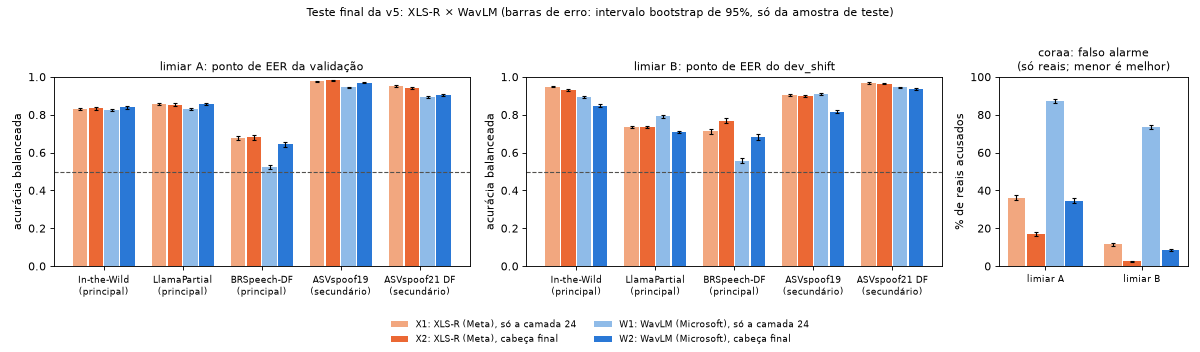

In [12]:
arq_tf = RESULTS_DIR / f"v5_teste_final{SUFIXO}.csv"
teste = None
if existe(arq_tf) and existe(RESULTS_DIR / f"v5_teste_final_concluido{SUFIXO}.json"):
    tf = pd.read_csv(arq_tf)
    tr5 = ler_json(RESULTS_DIR / f"v5_teste_final_resumo{SUFIXO}.json")
    teste = tf[tf.conjunto == "teste"]
    for L in ("A", "B"):
        p = teste[(teste.limiar == L) & teste["métrica"].isin(["AUC", "EER", "acurácia balanceada", "falso alarme real"])]
        display(Markdown(f"**Limiar {L}** ({'ponto de EER da validação' if L == 'A' else 'ponto de EER do dev_shift'}):"))
        display(p.pivot_table(index="banco", columns=["métrica", "sistema"], values="valor", sort=False).round(3))
    display(Markdown("**Resumo (média dos 3 bancos principais: In-the-Wild, LlamaPartialSpoof, BRSpeech-DF):**"))
    display(pd.DataFrame(tr5["resumo"]).round(3))
    print("reprodução (X2 da v5 × S2 da v4, AUC):",
          {b: round(v["dif"], 4) for b, v in tr5["reproducao_v4"].items()} if tr5.get("reproducao_v4") else "—")
    png = RESULTS_DIR / f"v5_teste_final{SUFIXO}.png"
    if existe(png):
        from IPython.display import Image
        display(Image(filename=str(png), width=900))
else:
    pendente("o teste final da v5 (python scripts/v5_teste.py)")

### 7.4 Leitura pré-definida: WavLM − XLS-R no teste
**O que faz:** mostra a diferença pareada (mesmas reamostragens) W2 − X2 e W1 − X1 em cada banco, com o intervalo de 95%, e a leitura da regra: **relevante** só com o mesmo sinal nos três bancos principais e o intervalo sem o zero em cada um. **Por quê:** a leitura foi fixada antes de ver o teste.

In [13]:
arq_d = RESULTS_DIR / f"v5_teste_diferencas{SUFIXO}.csv"
if teste is not None and existe(arq_d):
    display(pd.read_csv(arq_d).round(4))
    for k, v in tr5["regra_leitura"].items():
        print(f"{k}: {v}")

,leitura,métrica,banco,tipo,diferença,"IC 2,5%","IC 97,5%",IC exclui zero
0,"WavLM − XLS-R, cabeça final (W2 − X2)",AUC,in_the_wild,principal,-0.0285,-0.0319,-0.0246,True
1,"WavLM − XLS-R, cabeça final (W2 − X2)",AUC,llamapartialspoof,principal,-0.0100,-0.0135,-0.0062,True
2,"WavLM − XLS-R, cabeça final (W2 − X2)",AUC,brspeech_df,principal,-0.0748,-0.0839,-0.0662,True
3,"WavLM − XLS-R, cabeça final (W2 − X2)",AUC,asvspoof2019_la,secundário,-0.0027,-0.0036,-0.0019,True
4,"WavLM − XLS-R, cabeça final (W2 − X2)",AUC,asvspoof2021_df,secundário,-0.0061,-0.0074,-0.0048,True
5,"WavLM − XLS-R, cabeça final (W2 − X2)","acurácia balanceada, limiar A",in_the_wild,principal,0.0050,-0.0016,0.0123,False
6,"WavLM − XLS-R, cabeça final (W2 − X2)","acurácia balanceada, limiar A",llamapartialspoof,principal,0.0018,-0.0037,0.0073,False
7,"WavLM − XLS-R, cabeça final (W2 − X2)","acurácia balanceada, limiar A",brspeech_df,principal,-0.0372,-0.0477,-0.0269,True
8,"WavLM − XLS-R, cabeça final (W2 − X2)","acurácia balanceada, limiar A",asvspoof2019_la,secundário,-0.0113,-0.0148,-0.0082,True
9,"WavLM − XLS-R, cabeça final (W2 − X2)","acurácia balanceada, limiar A",asvspoof2021_df,secundário,-0.0378,-0.0432,-0.0324,True


WavLM − XLS-R, cabeça final (W2 − X2) | AUC: relevante: WavLM pior
WavLM − XLS-R, cabeça final (W2 − X2) | acurácia balanceada, limiar A: não demonstrada
WavLM − XLS-R, só camada 24 (W1 − X1) | AUC: relevante: WavLM pior
WavLM − XLS-R, só camada 24 (W1 − X1) | acurácia balanceada, limiar A: não demonstrada


**Conclusão do teste final:**
- **Em AUC, o WavLM é pior de forma demonstrada** nos três bancos principais (In-the-Wild −0,029, LlamaPartialSpoof −0,010, BRSpeech-DF −0,075) e também nos dois secundários.
- **Em acurácia balanceada (limiar A), a diferença não está demonstrada** no inglês (+0,005 e +0,002, com o zero no intervalo); só no pt-BR o WavLM perde (−0,037).
- **O pt-BR é onde a diferença é grande:** BRSpeech-DF AUC 0,842 × 0,768 e falso alarme no CORAA 16,9% × 34,5% (limiar A). Só com a última camada, o WavLM fica perto do acaso no BRSpeech-DF (0,557) e acusa 87% dos reais do CORAA. Faz sentido: o XLS-R viu 128 línguas no pré-treino, inclusive português; o WavLM Large, só inglês.
- **Reprodução:** o X2 repetiu o S2 da v4 no teste (diferença de AUC de no máximo 0,0008).

## 8. Experimentos e conclusões

**O que faz:** resume a v5 numa tabela. **Por quê:** é o que vai para o relatório e para a apresentação.

In [14]:
if cmp_ and teste is not None:
    res = []
    for s, m in (("X2", "xlsr"), ("W2", "wavlm")):
        t = teste[(teste.sistema == s) & (teste.limiar == "A")]
        g = lambda b, met: float(t[(t.banco == b) & (t["métrica"] == met)].valor.iloc[0])
        i = cmp_["sistemas"]["final"][m]
        res.append({"modelo": NOME[m], "val EER média por fonte": i["val EER média por fonte"], "dev_shift AUC": i["dev AUC"],
                    "In-the-Wild AUC": g("in_the_wild", "AUC"), "LlamaPartialSpoof AUC": g("llamapartialspoof", "AUC"),
                    "BRSpeech-DF AUC": g("brspeech_df", "AUC"), "CORAA falso alarme (A)": g("coraa", "falso alarme real")})
    display(pd.DataFrame(res).round(3))

,modelo,val EER média por fonte,dev_shift AUC,In-the-Wild AUC,LlamaPartialSpoof AUC,BRSpeech-DF AUC,CORAA falso alarme (A)
0,XLS-R (Meta),0.059,0.983,0.978,0.924,0.842,0.169
1,WavLM (Microsoft),0.068,0.970,0.950,0.914,0.768,0.345


**Conclusão da v5:**

1. **Resultado:** o **WavLM Large não superou o XLS-R**. Na decisão (validação + dev_shift), **empate pela regra**, com o WavLM atrás nas duas medidas. No teste final, **pior em AUC em todos os bancos** (de forma demonstrada), sobretudo em **português**. O projeto **segue com o XLS-R `concat_top3`** (camadas 5, 6 e 7).
2. **Por que o XLS-R ganhou:**
   - **Língua do pré-treino:** multilíngue (XLS-R) × só inglês (WavLM). É a maior diferença, e ela aparece no pt-BR.
   - **Onde ficam as pistas:** no WavLM, só nas camadas de baixo; nas de cima, ele parece "limpar" justamente o que denuncia a voz sintética (hipótese).
   - **Gravações antigas e áudios curtos** pioram ainda mais com o WavLM.
3. **Hipótese da v5** ("o WavLM, treinado com áudio sujo, generaliza melhor para vozes de internet"): **não confirmada**.
4. **Limitações:** uma única amostra de treino e uma regressão por sistema; dev_shift com só 16 locutores (por isso a decisão deu empate); o bootstrap do teste mede só a amostra de teste; os seis bancos de teste estavam consumidos desde a v4 (o teste da v5 só reporta); a explicação das camadas é hipótese; só dois modelos comparados.
5. **Para a v6** (em `docs/HISTORICO_VERSOES.md`, seção f): reais em pt-BR no treino; limiar por domínio; se for testar outro modelo, preferir um **multilíngue**; juntar as camadas de baixo do WavLM com as do meio do XLS-R (só decidindo pela validação + dev_shift).